# 04 · Caustics and lens geometry

The caustics of a binary lens depend on the separation *s* and mass ratio *q*: one resonant caustic near s = 1,
three caustics for close binaries, two for wide ones. `lenscape.caustics` computes caustics, critical curves,
source trajectories and magnification maps; `figures.plot_geometry` draws the configuration of a solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
from lenscape import caustics

## Topologies

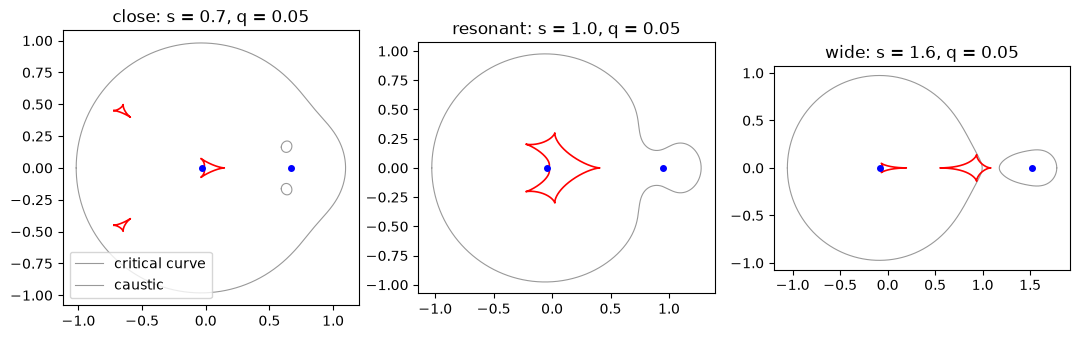

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (s, title) in zip(ax, ((0.7, "close"), (1.0, "resonant"), (1.6, "wide"))):
    crit, caus = caustics.critical_curves(s, 0.05)
    for c in crit:
        a.plot(c.real, c.imag, color="0.6", lw=0.8)
    for c in caus:
        a.plot(c.real, c.imag, color="red", lw=1.2)
    for x in caustics.lens_positions(s, 0.05):
        a.plot(x, 0, "bo", ms=4)
    a.set_aspect("equal"); a.set_title(f"{title}: s = {s}, q = 0.05")
ax[0].legend(["critical curve", "caustic"], loc="lower left");

## Magnification map and trajectory

`magnification_map` gives the point-source magnification on a grid of source positions; `trajectory(p, t)` the
source positions of a solution. The frame is centred on the centre of mass, primary on the left.

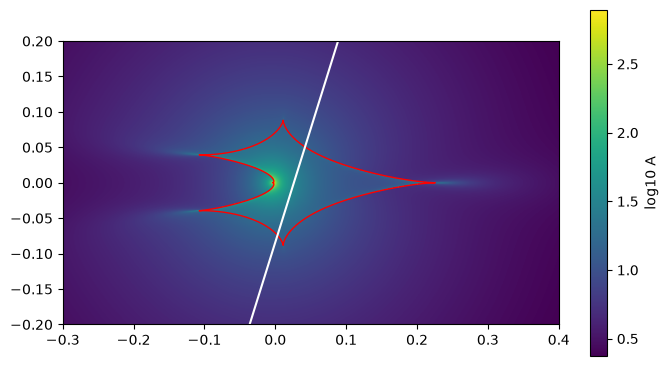

In [3]:
p = np.array([0.0, -0.025, 35.0, 0.002, -2.4, 4.41, -3.3])
s, q = 10 ** p[3], 10 ** p[4]
x, y = np.linspace(-0.3, 0.4, 500), np.linspace(-0.2, 0.2, 300)
A = caustics.magnification_map(s, q, x, y)
plt.figure(figsize=(8, 4.5))
plt.imshow(np.log10(A), origin="lower", extent=(x[0], x[-1], y[0], y[-1]), cmap="viridis")
plt.colorbar(label="log10 A")
for c in caustics.caustics(s, q):
    plt.plot(c.real, c.imag, "r", lw=1)
tr = caustics.trajectory(p, np.linspace(-10, 10, 200))
plt.plot(tr.real, tr.imag, "w"); plt.xlim(x[0], x[-1]); plt.ylim(y[0], y[-1]);

## Paper-style configuration plot

`plot_geometry` draws one panel per solution. Papers differ in their conventions: `centre="primary"` puts the
origin at the primary lens, and `mirror=True` reflects the picture about the binary axis (the reflection
(u0, α) → (−u0, −α) gives the same light curve).

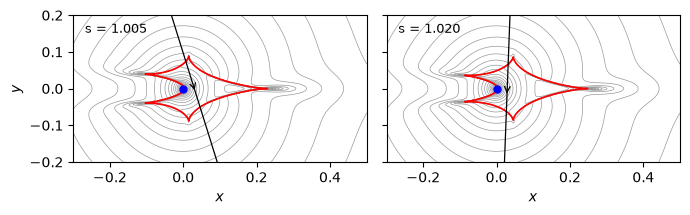

In [4]:
q2 = p.copy(); q2[3] = np.log10(1.02); q2[5] = 4.75
figures.plot_geometry([p, q2], labels=["s = 1.005", "s = 1.020"], mirror=True);